# 02 · Differentiating through time: autodiff for simulations, and first inverse problems

In notebook 01 we called `jax.grad` on a 50-step simulation and it just worked. Before we rely on that for a
multi-thousand-step hydro code, we need to know **what it costs, where it can go wrong, and what to do with gradients**.

**In this notebook you will:**
- see a simulation as a long chain of functions, and forward vs reverse mode as two ways of applying the chain rule,
- measure why reverse mode is the right tool when there are many inputs and one loss,
- measure reverse mode's memory bill and pay it down with **checkpointing** (`jax.checkpoint`),
- learn to **check gradients** and to spot the classic NaN traps,
- solve two inverse problems: recover a speed (and meet *flat loss landscapes*), then recover a **whole initial
  condition** (and meet *ill-posedness*, *priors* and *reparametrisation*).
- write a tiny **Adam** optimiser, which we will reuse for the rest of the series.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. A simulation is a chain of functions

A time-stepping code maps an initial state $u_0$ (and parameters $\theta$) to a final state through repeated steps,
$u_{n+1} = S(u_n; \theta)$, followed by a scalar loss $\mathcal L(u_N)$. The chain rule gives

$$\frac{\partial \mathcal L}{\partial u_0} = \frac{\partial \mathcal L}{\partial u_N}\, \underbrace{\frac{\partial S}{\partial u}\Big|_{u_{N-1}}}_{J_N} \cdots \underbrace{\frac{\partial S}{\partial u}\Big|_{u_0}}_{J_1}.$$

We never form the $N_\text{cells}\times N_\text{cells}$ Jacobians. Instead we multiply them against vectors, in one of two orders:

* **Forward mode** (JVP, `jax.jvp`, `jax.jacfwd`) pushes a *tangent* $\dot u_0$ through the chain alongside the
  simulation: $\dot u_{n+1} = J_{n+1}\dot u_n$. One pass gives the derivative along **one input direction**, for every output.
* **Reverse mode** (VJP, `jax.vjp`, `jax.grad`) pulls a *cotangent* $\bar u_N = \partial\mathcal L/\partial u_N$
  backwards: $\bar u_{n} = J_{n+1}^\top \bar u_{n+1}$. One backward pass gives the derivative of **one output** with respect
  to every input. The catch is that $J_{n+1}$ depends on $u_n$, so the forward states must be **stored** (or recomputed).

This "backward-in-time" sweep is the **adjoint method** of optimal control and data assimilation; `jax.grad` derives
it automatically. Let's build a small solver to experiment with: viscous Burgers,
$\partial_t u + \partial_x(u^2/2) = \nu\,\partial_x^2 u$, with the Rusanov flux from notebook 01 plus a diffusive flux.

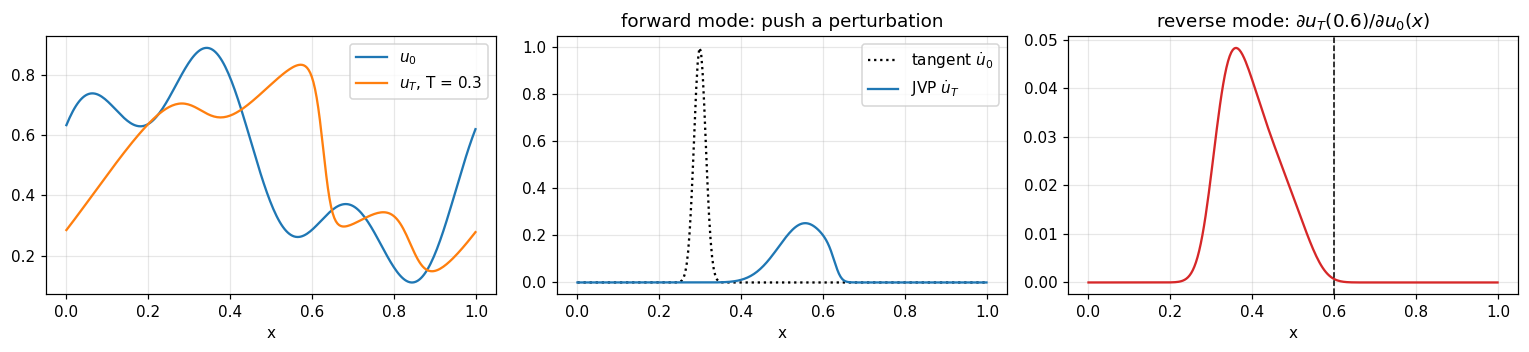

In [2]:
N, L = 256, 1.0
dx = L / N
x = (np.arange(N) + 0.5) * dx
nu = 2e-3

def burgers_step(u, dt):
    uR = jnp.roll(u, -1)
    s = jnp.maximum(jnp.abs(u), jnp.abs(uR))
    F = 0.25 * (u ** 2 + uR ** 2) - 0.5 * s * (uR - u)    # Rusanov advective flux at i+1/2
    F = F - nu * (uR - u) / dx                           # viscous flux
    return u - dt / dx * (F - jnp.roll(F, 1))

def simulate(u0, dt=1e-3, nsteps=300):
    # lax.scan = a differentiable for-loop that carries state (and can stack per-step outputs)
    u_final, _ = jax.lax.scan(lambda u, _: (burgers_step(u, dt), None), u0, None, length=nsteps)
    return u_final

u0 = 0.5 + 0.3 * jnp.sin(2 * np.pi * x) + 0.15 * jnp.sin(6 * np.pi * x + 1.0)
uT = simulate(u0)

# JVP: how does the final state respond to a localized bump in the initial state?
bump = jnp.exp(-((x - 0.3) / 0.02) ** 2)
_, du_T = jax.jvp(simulate, (u0,), (bump,))

# VJP: which initial cells influence the final value at x = 0.6?
i_probe = int(0.6 / dx)
_, vjp_fn = jax.vjp(simulate, u0)
(sens,) = vjp_fn(jnp.zeros(N).at[i_probe].set(1.0))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
axes[0].plot(x, u0, label="$u_0$"); axes[0].plot(x, uT, label="$u_T$, T = 0.3"); axes[0].legend()
axes[1].plot(x, bump, "k:", label=r"tangent $\dot u_0$"); axes[1].plot(x, du_T, label=r"JVP $\dot u_T$"); axes[1].legend()
axes[1].set_title("forward mode: push a perturbation")
axes[2].plot(x, sens, color="C3"); axes[2].axvline(0.6, color="k", ls="--", lw=1)
axes[2].set_title(r"reverse mode: $\partial u_T(0.6)/\partial u_0(x)$")
for ax in axes: ax.set_xlabel("x")
plt.tight_layout()

The JVP panel shows the bump being carried to the right and spread by viscosity. The VJP panel is its mirror image:
the probe at $x = 0.6$ is only sensitive to a *domain of dependence* upstream of it, which is roughly where the
characteristics that arrive at $x=0.6$ started.

### Many inputs → reverse mode

A full Jacobian costs $N_\text{in}$ forward-mode passes or $N_\text{out}$ reverse-mode passes. Inverse problems have
**one scalar loss and many inputs** (an entire initial field), so reverse mode wins by a factor of $N_\text{in}$:

In [3]:
def loss(u0, data):
    return jnp.mean((simulate(u0, nsteps=100) - data) ** 2)

sizes, t_rev, t_fwd = [64, 128, 256, 512], [], []
for n in sizes:
    xx = (np.arange(n) + 0.5) / n
    u_init = 0.5 + 0.3 * jnp.sin(2 * np.pi * xx)
    g_rev = jax.jit(jax.grad(loss))
    g_fwd = jax.jit(jax.jacfwd(loss))          # same gradient, built from n JVPs
    for f, store in ((g_rev, t_rev), (g_fwd, t_fwd)):
        f(u_init, u_init).block_until_ready()  # compile
        t0 = time.perf_counter(); f(u_init, u_init).block_until_ready()
        store.append(time.perf_counter() - t0)
    print(f"n={n:4d}  reverse {t_rev[-1] * 1e3:7.2f} ms   forward {t_fwd[-1] * 1e3:8.2f} ms   "
          f"ratio {t_fwd[-1] / t_rev[-1]:5.1f}   "
          f"max diff {float(jnp.abs(g_rev(u_init, u_init) - g_fwd(u_init, u_init)).max()):.1e}")

n=  64  reverse    0.90 ms   forward     2.47 ms   ratio   2.8   max diff 6.9e-18


n= 128  reverse    1.27 ms   forward    11.86 ms   ratio   9.3   max diff 3.5e-18


n= 256  reverse    4.27 ms   forward    40.64 ms   ratio   9.5   max diff 8.7e-19


n= 512  reverse    4.66 ms   forward    42.55 ms   ratio   9.1   max diff 2.4e-19


(`dx` and `nu` are globals of the solver, so these runs are not physically identical across $n$; only the scaling matters here.)
Both get slower with $n$ because the simulation itself is bigger, but forward mode has to push $n$ tangent
vectors through it, against a single backward pass for reverse mode. `jacfwd` batches those tangents with `vmap`,
which a multicore CPU partly absorbs at these small sizes, so the measured ratio is "only" ~10×. The work, and the
memory, still grow with $n$. For the $2 \times 128^2$ white-noise inputs of notebook 06 forward mode would need
32 768 tangents per gradient. From here on: `jax.grad`.

## 2. The memory bill and checkpointing

Reverse mode needs every intermediate state $u_n$ during the backward sweep, so memory grows **linearly with the
number of steps**. A 3D hydro run with $256^3 \times 5$ fields and thousands of steps does not fit on any GPU that way.

**Checkpointing** (a.k.a. rematerialisation) trades compute for memory: store only every $B$-th state and recompute
the states inside each block during the backward pass. In JAX that is `jax.checkpoint` (alias `jax.remat`) wrapped
around a block of steps. With $B \approx \sqrt{N_\text{steps}}$ the memory drops from $\mathcal O(N)$ to
$\mathcal O(\sqrt N)$ for roughly one extra forward pass. We can ask XLA how much scratch memory each compiled gradient needs:

state size: 2048 bytes;  plain/step: 12800.0 bytes


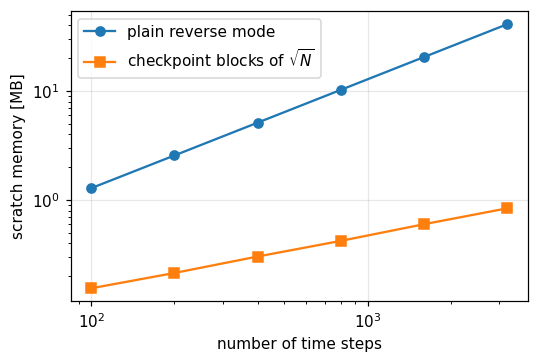

In [4]:
def simulate_checkpointed(u0, dt=1e-3, nsteps=300, block=20):
    def block_fn(u, _):
        u, _ = jax.lax.scan(lambda u, _: (burgers_step(u, dt), None), u, None, length=block)
        return u, None
    u_final, _ = jax.lax.scan(jax.checkpoint(block_fn), u0, None, length=nsteps // block)
    return u_final

def temp_memory(fn, nsteps):
    g = jax.jit(jax.grad(lambda u: jnp.sum(fn(u, nsteps=nsteps) ** 2)))
    return g.lower(u0).compile().memory_analysis().temp_size_in_bytes

steps = [100, 200, 400, 800, 1600, 3200]
mem_plain = [temp_memory(simulate, n) for n in steps]
mem_ckpt = [temp_memory(lambda u, nsteps: simulate_checkpointed(u, nsteps=nsteps, block=int(np.sqrt(nsteps))), n)
            for n in steps]

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.loglog(steps, np.array(mem_plain) / 1e6, "o-", label="plain reverse mode")
ax.loglog(steps, np.array(mem_ckpt) / 1e6, "s-", label=r"checkpoint blocks of $\sqrt{N}$")
ax.set_xlabel("number of time steps"); ax.set_ylabel("scratch memory [MB]"); ax.legend()
plt.tight_layout()
print("state size:", u0.nbytes, "bytes;  plain/step:", (mem_plain[-1] - mem_plain[-2]) / (steps[-1] - steps[-2]), "bytes")

Plain reverse mode stores everything each step's VJP needs (here ~6 arrays the size of the state per step: the
state itself, the face fluxes, the wave speeds …); checkpointing grows like $\sqrt N$. diffhydro uses exactly this trick
(`hydro.evolve_memory_efficient(..., checkpoint_every=10)` and a `jax.checkpoint` around each step in
`evolve_with_dt_schedule`). That is what makes gradients through thousands of 3D steps feasible.

## 3. Trust, but verify: gradient checks

Autodiff is exact *for the code you wrote*. Bugs, non-differentiable operations or numerical trouble still show up, so
**always check a gradient against finite differences** along a random direction $v$:
$\nabla\mathcal L\cdot v \approx [\mathcal L(u+\epsilon v) - \mathcal L(u-\epsilon v)]/2\epsilon$.
The step $\epsilon$ is a trade-off: truncation error $\propto\epsilon^2$ against round-off $\propto \text{machine-}\epsilon/\epsilon$.

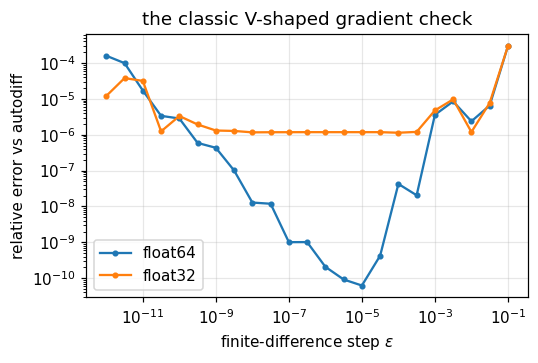

In [5]:
data = simulate(u0 + 0.05 * jnp.cos(4 * np.pi * x), nsteps=100)
v = jax.random.normal(jax.random.PRNGKey(0), (N,))

def directional_check(dtype):
    u, d, vv = u0.astype(dtype), data.astype(dtype), v.astype(dtype)
    g_dot_v = jnp.dot(jax.grad(loss)(u, d), vv)
    eps = np.logspace(-12, -1, 23)
    fd = np.array([(loss(u + e * vv, d) - loss(u - e * vv, d)) / (2 * e) for e in eps])
    return eps, np.abs(fd - g_dot_v) / np.abs(g_dot_v)

fig, ax = plt.subplots(figsize=(5, 3.4))
for dt_ in (jnp.float64, jnp.float32):
    eps, rel = directional_check(dt_)
    ax.loglog(eps, rel, "o-", ms=3, label=jnp.dtype(dt_).name)
ax.set_xlabel(r"finite-difference step $\epsilon$"); ax.set_ylabel("relative error vs autodiff"); ax.legend()
ax.set_title("the classic V-shaped gradient check")
plt.tight_layout()

In float64 autodiff and finite differences agree to ~$10^{-10}$ at the optimal $\epsilon$. In float32 the best you can
hope for is ~$10^{-3}$, which is worth remembering: diffhydro runs in float32 on GPUs, so its gradient checks use loose tolerances.

## 4. Where gradients go wrong

Most problems come from operations whose **forward value is fine but whose derivative is not**.

**(a) $\sqrt{\cdot}$ at zero.** The speed $|\mathbf v| = \sqrt{v_x^2 + v_y^2}$ appears in every Riemann solver. At $\mathbf v = 0$ its
derivative is $0 \times \infty$:

In [6]:
speed = lambda v: jnp.sqrt(jnp.sum(v ** 2))
print("grad |v| at v = (0.3, 0.4):", jax.grad(speed)(jnp.array([0.3, 0.4])))
print("grad |v| at v = (0, 0)    :", jax.grad(speed)(jnp.array([0.0, 0.0])))

# |v|^b with b < 2 has the same disease (e.g. drag laws, turbulent closures)
print("grad |v|^1.5 at v = 0     :", jax.grad(lambda v: jnp.sum(v ** 2) ** 0.75)(jnp.array([0.0, 0.0])))

grad |v| at v = (0.3, 0.4): [0.6 0.8]
grad |v| at v = (0, 0)    : [nan nan]
grad |v|^1.5 at v = 0     : [nan nan]


**(b) The `jnp.where` trap.** `where` selects values, but reverse mode differentiates **both** branches and multiplies
the unselected one by zero. If the unselected branch has an infinite or NaN derivative, then $0\times\infty = $ NaN:

In [7]:
bad = lambda x: jnp.where(x > 0, jnp.sqrt(x), 0.0)
print("forward value at x = 0:", bad(0.0), "   grad:", jax.grad(bad)(0.0))

# the fix: make the *input* of the dangerous op safe too ("double where")
def good(x):
    x_safe = jnp.where(x > 0, x, 1.0)
    return jnp.where(x > 0, jnp.sqrt(x_safe), 0.0)
print("double-where fix                grad:", jax.grad(good)(0.0))

forward value at x = 0: 0.0    grad: nan
double-where fix                grad: 0.0


These are not academic. A fluid initialised **exactly at rest** puts every cell at $\mathbf v = 0$, so the adjoint
blows up. In notebook 05 we will always start turbulence with a small non-zero velocity for exactly this reason.
`jax.config.update("jax_debug_nans", True)` makes JAX stop at the first NaN, which is the fastest way to find such ops.

**(c) Kinks.** `abs`, `max`, `min` and slope *limiters* are continuous but not differentiable at their switching points.
JAX returns a one-sided derivative there. Losses built from them are piecewise smooth, which gradient methods
handle fine in practice, but finite-difference checks straddling a kink will disagree.

**(d) Chaos.** For long time horizons in turbulent flows, $\partial u_T/\partial u_0$ grows exponentially. The gradient is
*correct* but useless for optimisation. We will measure this in notebook 05.

## 5. Inverse problem I: recover a speed, and meet flat landscapes

Simplest possible inverse problem: a narrow pulse was advected with an unknown speed $a_\text{true}$; we observe the
final profile and want $a$. We'll write the optimiser ourselves.

**Gradient descent:** $\theta \leftarrow \theta - \eta\,\nabla\mathcal L$. Simple, but the right step size $\eta$ depends on
the scale of the gradient, which can differ by orders of magnitude between parameters and over the course of the fit.

**Adam** (Kingma & Ba 2015) keeps running averages of the gradient ($m$) and its square ($v$) and steps by
$\eta\,\hat m/(\sqrt{\hat v}+\epsilon)$. That is a per-parameter step of size ~$\eta$ *regardless of the gradient's scale*.
It's ~10 lines on JAX pytrees (dicts/lists/tuples of arrays). We put an identical copy in `tutorial_utils.py` for later notebooks:

In [8]:
def adam_init(params):
    zeros = jax.tree_util.tree_map(jnp.zeros_like, params)
    return {"m": zeros, "v": zeros, "t": 0}

def adam_step(params, grads, state, lr, b1=0.9, b2=0.999, eps=1e-8):
    t = state["t"] + 1
    m = jax.tree_util.tree_map(lambda m, g: b1 * m + (1 - b1) * g, state["m"], grads)
    v = jax.tree_util.tree_map(lambda v, g: b2 * v + (1 - b2) * g * g, state["v"], grads)
    mhat_scale, vhat_scale = 1.0 / (1 - b1 ** t), 1.0 / (1 - b2 ** t)   # bias correction
    params = jax.tree_util.tree_map(
        lambda p, m, v: p - lr * (m * mhat_scale) / (jnp.sqrt(v * vhat_scale) + eps), params, m, v)
    return params, {"m": m, "v": v, "t": t}

final a: sharp -1.4150   coarse-to-fine 0.5939   (true 0.6)


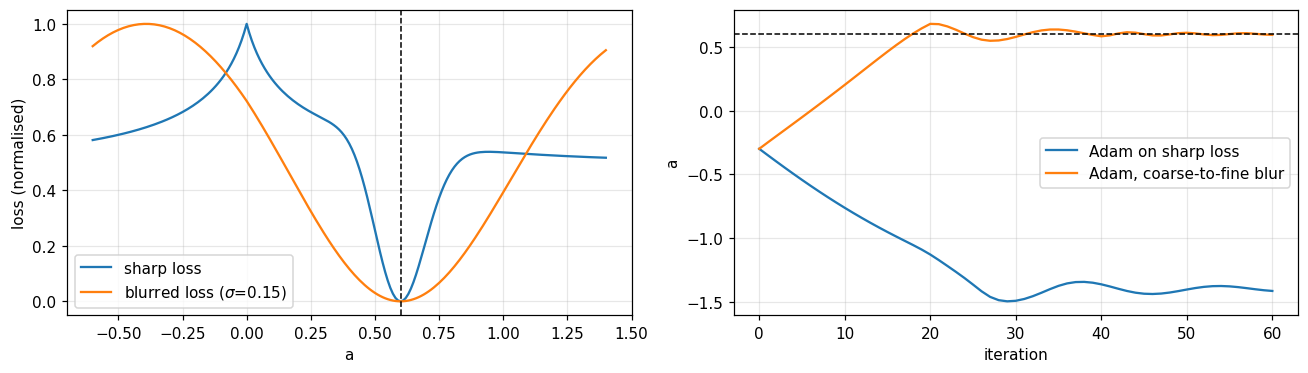

In [9]:
def advect(u0, a, dt=1e-3, nsteps=500):          # T = 0.5, periodic box of length 1
    def step(u, _):
        F = 0.5 * a * (u + jnp.roll(u, -1)) - 0.5 * jnp.abs(a) * (jnp.roll(u, -1) - u)
        return u - dt / dx * (F - jnp.roll(F, 1)), None
    return jax.lax.scan(step, u0, None, length=nsteps)[0]

pulse = jnp.exp(-((x - 0.25) / 0.02) ** 2)
a_true = 0.6
d_obs = advect(pulse, a_true)

def gaussian_blur(f, sigma):
    # periodic Gaussian smoothing via FFT; sigma in box units
    k = 2 * np.pi * np.fft.fftfreq(N, d=dx)
    return jnp.fft.ifft(jnp.fft.fft(f) * jnp.exp(-0.5 * (k * sigma) ** 2)).real

def loss_speed(a, sigma=0.0):
    r = advect(pulse, a) - d_obs
    return jnp.mean((gaussian_blur(r, sigma) if sigma > 0 else r) ** 2)

a_grid = np.linspace(-0.6, 1.4, 201)
L_sharp = jax.vmap(loss_speed)(a_grid)                    # vmap: evaluate the whole landscape in one batched call
L_blur = jax.vmap(lambda a: loss_speed(a, 0.15))(a_grid)

def fit(a0, sigma_schedule, lr=0.05, iters=60):
    p, st, path = jnp.array(a0), adam_init(jnp.array(a0)), [a0]
    for i in range(iters):
        sigma = sigma_schedule[min(i * len(sigma_schedule) // iters, len(sigma_schedule) - 1)]
        g = jax.grad(loss_speed)(p, sigma)
        p, st = adam_step(p, g, st, lr)
        path.append(float(p))
    return np.array(path)

path_sharp = fit(-0.3, [0.0])
path_c2f = fit(-0.3, [0.15, 0.05, 0.0])

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 3.5))
ax0.plot(a_grid, L_sharp / L_sharp.max(), label="sharp loss")
ax0.plot(a_grid, L_blur / L_blur.max(), label=r"blurred loss ($\sigma$=0.15)")
ax0.axvline(a_true, color="k", ls="--", lw=1); ax0.set_xlabel("a"); ax0.set_ylabel("loss (normalised)"); ax0.legend()
ax1.plot(path_sharp, label="Adam on sharp loss"); ax1.plot(path_c2f, label="Adam, coarse-to-fine blur")
ax1.axhline(a_true, color="k", ls="--", lw=1); ax1.set_xlabel("iteration"); ax1.set_ylabel("a"); ax1.legend()
plt.tight_layout()
print(f"final a: sharp {path_sharp[-1]:.4f}   coarse-to-fine {path_c2f[-1]:.4f}   (true {a_true})")

The sharp loss has a narrow basin around $a_\text{true}$; outside it the gradient carries no information about
*where* the observed pulse is. Worse, here it points the **wrong way**. When the pulses do not overlap, the cheapest way
to lower the squared mismatch is to *smear the predicted pulse out*, and numerical diffusion grows with $|a|$
(notebook 01), so Adam runs off to large negative $a$. Note also the kink at $a=0$ from the $|a|$ in the Rusanov flux:
pitfall (c) in action. Comparing **blurred** residuals
widens the basin of attraction. Annealing the blur ($\sigma = 0.15 \to 0.05 \to 0$) keeps the final answer exact.
We will use the same **coarse-to-fine** trick to make turbulence write a letter in notebook 06.

## 6. Inverse problem II: recover an entire initial condition

Now the real thing: observe a noisy final state $d = u_T + n$ of viscous Burgers and recover all 256 values of $u_0$.

In [10]:
rng = np.random.default_rng(1)
def smooth_random_field(seed, kmax=6):
    r = np.random.default_rng(seed)
    f = sum(r.normal() / k * np.sin(2 * np.pi * k * x + r.uniform(0, 2 * np.pi)) for k in range(1, kmax + 1))
    return f / f.std()

u0_true = jnp.asarray(0.5 + 0.25 * smooth_random_field(3))
noise = 0.01
d = simulate(u0_true) + noise * jnp.asarray(rng.standard_normal(N))

def data_loss(u_init):
    return jnp.mean((simulate(u_init) - d) ** 2) / noise ** 2   # chi^2 per cell: ~1 means "fits to the noise"

@jax.jit
def vg_pixels(u_init):
    return jax.value_and_grad(data_loss)(u_init)

def run_opt(vg, p0, lr, iters, use_adam=True):
    p, st, hist = p0, adam_init(p0), []
    for i in range(iters):
        l, g = vg(p)
        p, st = adam_step(p, g, st, lr) if use_adam else (p - lr * g, st)
        hist.append(float(l))
    return p, np.array(hist)

u_start = jnp.full(N, 0.5)
u_gd, h_gd = run_opt(vg_pixels, u_start, lr=2e-4, iters=400, use_adam=False)
u_adam, h_adam = run_opt(vg_pixels, u_start, lr=1e-2, iters=400)
print(f"final chi^2/cell: GD {h_gd[-1]:.2f}   Adam {h_adam[-1]:.2f}")

final chi^2/cell: GD 1.47   Adam 0.82


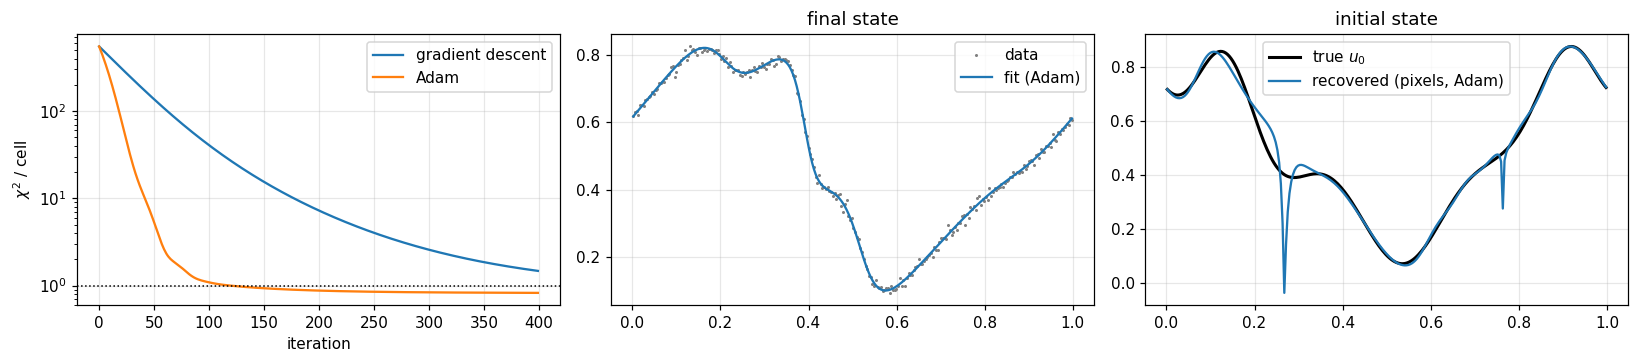

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
axes[0].semilogy(h_gd, label="gradient descent"); axes[0].semilogy(h_adam, label="Adam")
axes[0].axhline(1, color="k", ls=":", lw=1); axes[0].set_xlabel("iteration"); axes[0].set_ylabel(r"$\chi^2$ / cell"); axes[0].legend()
axes[1].plot(x, d, ".", ms=2, color="gray", label="data"); axes[1].plot(x, simulate(u_adam), label="fit (Adam)")
axes[1].set_title("final state"); axes[1].legend()
axes[2].plot(x, u0_true, "k", lw=2, label="true $u_0$"); axes[2].plot(x, u_adam, label="recovered (pixels, Adam)")
axes[2].set_title("initial state"); axes[2].legend()
plt.tight_layout()

Adam fits the data to the noise level much faster than plain gradient descent, whose stable step size is set by the
stiffest direction. It even goes *below* $\chi^2 = 1$, i.e. it starts fitting the noise.
But look at the **recovered initial condition**: it reproduces the data while wiggling around the truth.
That is not an optimiser failure; the problem is **ill-posed**:

* **viscosity erases small scales**: a mode $e^{ikx}$ decays like $e^{-\nu k^2 T}$, so high-$k$ structure in $u_0$
  barely affects $u_T$, and noise at those scales in the data gets *amplified* back into $u_0$;
* **shocks erase information**: characteristics that run into a shock are lost, so many different $u_0$ give the same $u_T$.

The cure is to say what kind of initial condition we expect: a **prior**. The cleanest version is to
*reparametrise*. Write $u_0 = \bar u + \mathcal F^{-1}[A(k)\,\mathcal F[w]]$, where $w$ is a white-noise field with
prior $w\sim\mathcal N(0,1)$ and $A(k) = \sqrt{P(k)}$ is the expected amplitude spectrum. With Gaussian noise,
$-2\ln(\text{posterior}) = \chi^2 + \|w\|^2$, so minimising `mean(chi^2) + λ·mean(w^2)` with $\lambda = 1$ (we have
as many data points as parameters) is exactly the **maximum-a-posteriori** estimate. In practice λ is often tuned.
A side benefit is that the optimiser sees well-conditioned, order-unity parameters.

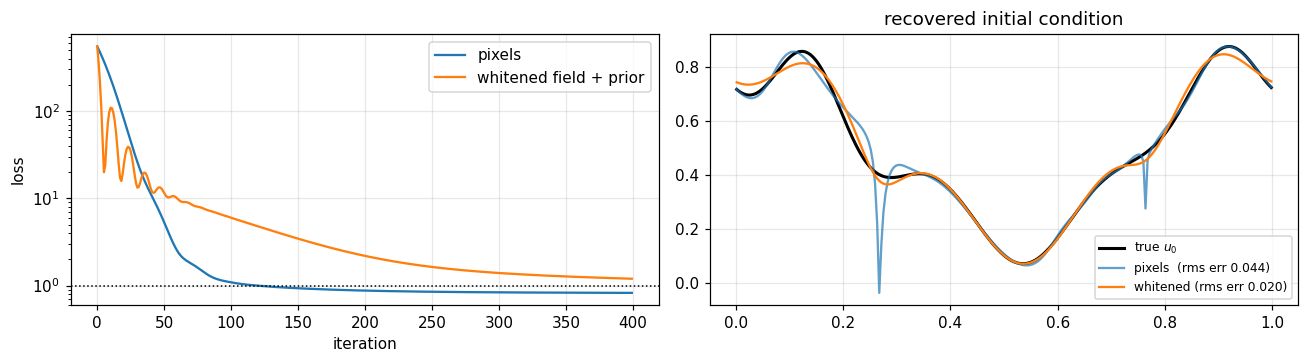

In [12]:
k = np.fft.fftfreq(N, d=1.0 / N)                       # integer wavenumbers
amp = np.where(k != 0, 1.0 / np.maximum(np.abs(k), 1) ** 1.5 * np.exp(-(k / 12.0) ** 2), 0.0)
amp = jnp.asarray(amp / np.sqrt(np.mean(amp ** 2)) * 0.25)   # unit-variance w -> 0.25 rms u0 fluctuation

def u0_from_w(w):
    return 0.5 + jnp.fft.ifft(jnp.fft.fft(w) * amp).real

lam = 1.0
@jax.jit
def vg_whitened(w):
    return jax.value_and_grad(lambda w: data_loss(u0_from_w(w)) + lam * jnp.mean(w ** 2))(w)

w_fit, h_w = run_opt(vg_whitened, jnp.zeros(N), lr=2e-2, iters=400)
u_w = u0_from_w(w_fit)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].semilogy(h_adam, label="pixels"); axes[0].semilogy(h_w, label="whitened field + prior")
axes[0].axhline(1, color="k", ls=":", lw=1); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("loss"); axes[0].legend()
axes[1].plot(x, u0_true, "k", lw=2, label="true $u_0$")
axes[1].plot(x, u_adam, alpha=0.7, label=f"pixels  (rms err {float(jnp.sqrt(jnp.mean((u_adam - u0_true) ** 2))):.3f})")
axes[1].plot(x, u_w, label=f"whitened (rms err {float(jnp.sqrt(jnp.mean((u_w - u0_true) ** 2))):.3f})")
axes[1].legend(fontsize=8); axes[1].set_title("recovered initial condition")
plt.tight_layout()

With the prior, the recovered initial condition is smooth and much closer to the truth. Where it still misses,
the information was genuinely destroyed (look near the shocks).

## Summary and what's next

* `jax.grad` through a time loop is the **adjoint method**. One backward sweep gives the gradient with respect to every input.
* Its memory grows with the number of steps; **checkpointing** brings that down to ~$\sqrt{N}$ for ~1 extra forward pass.
* **Check gradients** against finite differences, and watch for `sqrt`/`where`/`|v|^b` at zero and other kinks.
* Inverse problems need help: **coarse-to-fine** losses widen basins, and **priors via reparametrisation** (whitened
  Gaussian fields) tame ill-posedness. **Adam** handles badly scaled gradients.

So far the physics has been a toy. In **notebook 03** we write a real compressible-flow solver for the 1D Euler equations
(Riemann problems, HLLC, MUSCL reconstruction), validate it against the exact solution, and differentiate through shocks!